# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [40]:
!pip install polars

In [41]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.

# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).
import polars as pl
import polars.selectors as cs
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch 
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

torch.manual_seed(42)
np.random.seed(42)

In [42]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [43]:
!unzip -q -o fashion-mnist_train.csv.zip

In [44]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.


dataset = pl.read_csv("fashion-mnist_train.csv")
test_dataset = pl.read_csv("fashion-mnist_test.csv")


In [45]:
dataset.shape, test_dataset.shape

((60000, 785), (10000, 785))

Text(0.5, 1.0, 'Distribution of Classes in Train Set')

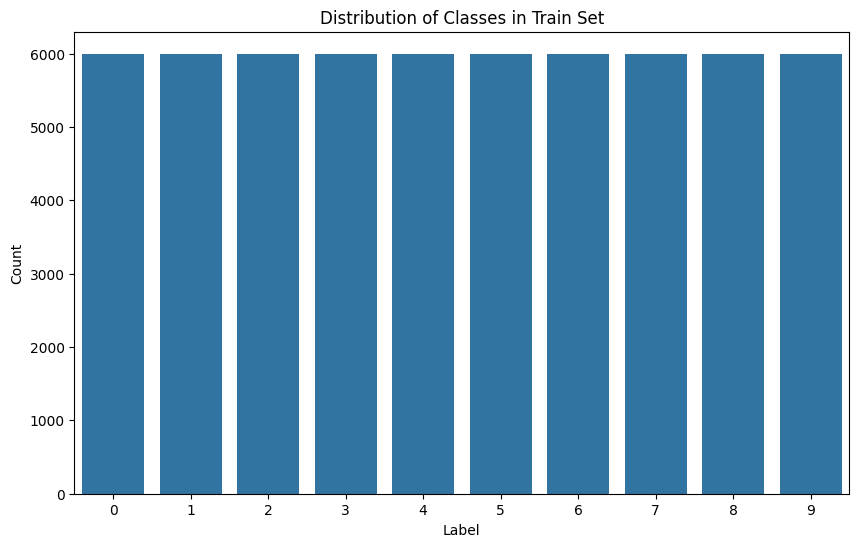

In [46]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

plt.figure(figsize=(10, 6))
sns.countplot(x="label", data=dataset.to_pandas())
plt.xlabel("Label")
plt.ylabel("Count")
plt.title("Distribution of Classes in Train Set")

summa balanced.

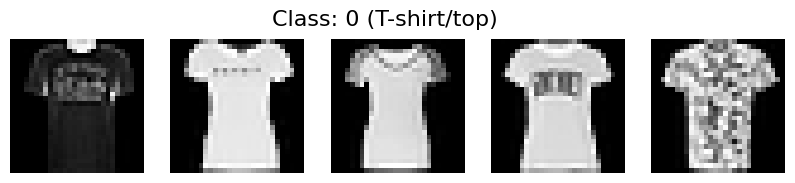

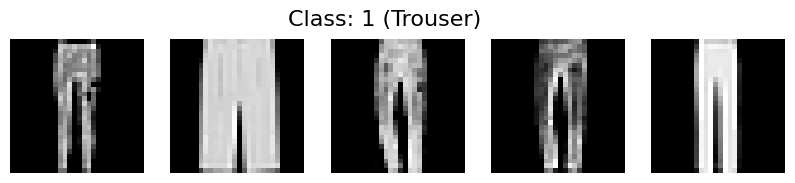

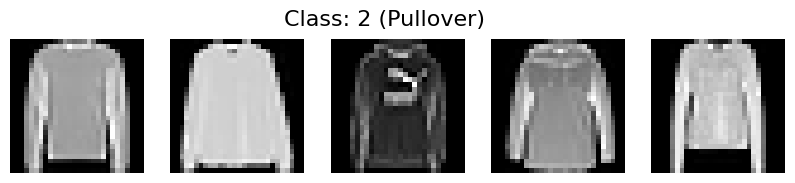

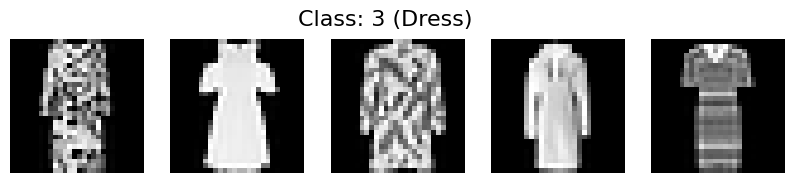

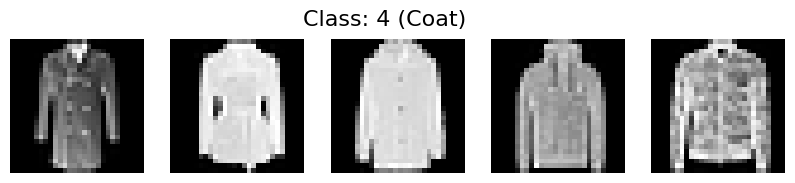

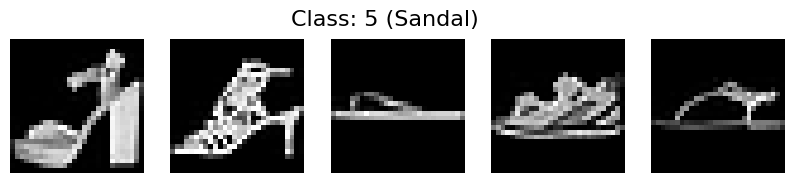

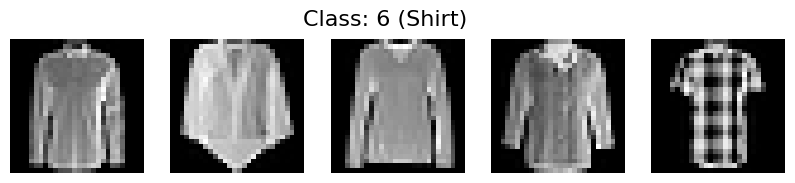

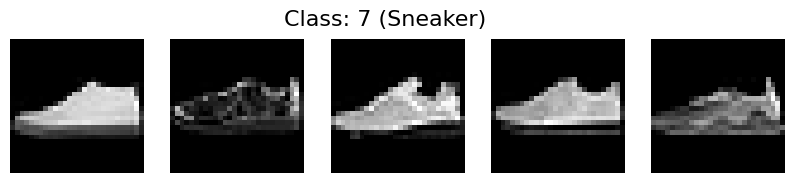

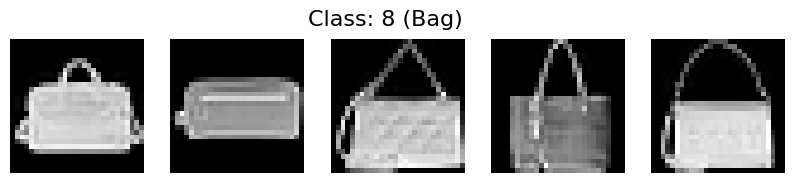

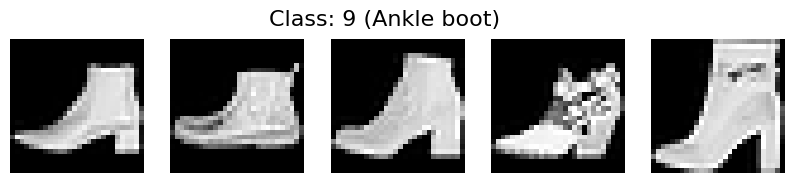

In [47]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

for label in range(10):
    plt.figure(figsize=(10, 2))
    plt.suptitle(f"Class: {label} ({class_names[label]})", fontsize=16)
    
    class_rows = dataset.filter(pl.col("label") == label).sample(n=5, seed=42)
    
    for i, row in enumerate(class_rows.iter_rows()):
        pixels = np.array(row[1:], dtype=np.uint8).reshape(28, 28)
        plt.subplot(1, 5, i + 1)
        plt.imshow(pixels, cmap="gray")
        plt.axis("off")
    
    plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [48]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train = dataset.select(cs.exclude("label")).to_numpy()
y_train = dataset.select("label").to_numpy().flatten()

X_test = test_dataset.select(cs.exclude("label")).to_numpy()
y_test = test_dataset.select("label").to_numpy().flatten()

In [49]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [50]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=42, stratify=y_train
)

In [58]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long).squeeze()  # Mengubah bentuk menjadi (N,)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long).squeeze()  # Mengubah bentuk menjadi (N,)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long).squeeze()  # Mengubah bentuk menjadi (N,)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [52]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self, input_size=784, output_size=10):
        super(ANN, self).__init__()
        self.fc1 = nn.Linear(input_size, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, output_size)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.2)

    def forward(self, x):
        x = x.view(-1, 784)  # Flatten the input
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.relu(self.fc3(x))
        x = self.dropout(x)
        x = self.fc4(x)
        return x

model_ANN = ANN().to(device)

for param in model_ANN.parameters():
    print(param.shape, param.numel())


torch.Size([256, 784]) 200704
torch.Size([256]) 256
torch.Size([128, 256]) 32768
torch.Size([128]) 128
torch.Size([64, 128]) 8192
torch.Size([64]) 64
torch.Size([10, 64]) 640
torch.Size([10]) 10


#### Train Function

In [ ]:
def train_model(model, train_loader, val_loader, loss_fn, optimizer, num_epochs, device, log_interval=1):
    model.to(device)
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train = 0

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = loss_fn(outputs, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * X_batch.size(0)
            predicted = torch.argmax(outputs, dim=1)
            correct_train += (predicted == y_batch).sum().item()
            total_train += y_batch.size(0)

        train_loss /= total_train
        train_acc = correct_train / total_train

        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for X_val_batch, y_val_batch in val_loader:
                X_val_batch, y_val_batch = X_val_batch.to(device), y_val_batch.to(device)
                
                val_outputs = model(X_val_batch)
                v_loss = loss_fn(val_outputs, y_val_batch)

                val_loss += v_loss.item() * X_val_batch.size(0)
                predicted_val = torch.argmax(val_outputs, dim=)
                correct_val += (predicted_val == y_val_batch).sum().item()
                total_val += y_val_batch.size(0)

        val_loss /= total_val
        val_acc = correct_val / total_val

        if (epoch + 1) % log_interval == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

    return history

Epoch [1/15], Train Loss: 0.5238, Train Acc: 0.8125, Val Loss: 0.4055, Val Acc: 0.8533
Epoch [2/15], Train Loss: 0.4032, Train Acc: 0.8571, Val Loss: 0.3740, Val Acc: 0.8603
Epoch [3/15], Train Loss: 0.3731, Train Acc: 0.8681, Val Loss: 0.3503, Val Acc: 0.8743
Epoch [4/15], Train Loss: 0.3494, Train Acc: 0.8760, Val Loss: 0.3321, Val Acc: 0.8817
Epoch [5/15], Train Loss: 0.3322, Train Acc: 0.8805, Val Loss: 0.3636, Val Acc: 0.8668
Epoch [6/15], Train Loss: 0.3183, Train Acc: 0.8840, Val Loss: 0.3367, Val Acc: 0.8805
Epoch [7/15], Train Loss: 0.3062, Train Acc: 0.8891, Val Loss: 0.3354, Val Acc: 0.8817
Epoch [8/15], Train Loss: 0.2986, Train Acc: 0.8921, Val Loss: 0.3231, Val Acc: 0.8888
Epoch [9/15], Train Loss: 0.2876, Train Acc: 0.8959, Val Loss: 0.3391, Val Acc: 0.8783
Epoch [10/15], Train Loss: 0.2812, Train Acc: 0.8982, Val Loss: 0.3283, Val Acc: 0.8830
Epoch [11/15], Train Loss: 0.2723, Train Acc: 0.9011, Val Loss: 0.3444, Val Acc: 0.8842
Epoch [12/15], Train Loss: 0.2735, Train 

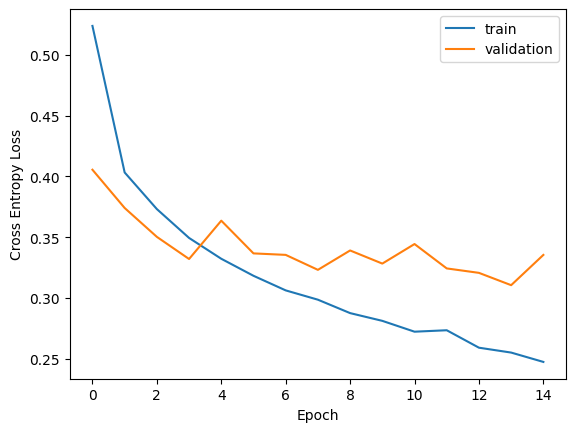

In [60]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
from torch.optim import Adam
from torch.nn import CrossEntropyLoss


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_ANN = ANN(X_train_tensor.shape[1]).to(device)
loss_fn = CrossEntropyLoss()
optimizer = Adam(model_ANN.parameters(), lr=1e-3)
epochs = 15

history = train_model(
    model_ANN, train_loader, val_loader, loss_fn, optimizer, num_epochs=epochs, device=device
)
plt.plot(history["train_loss"], label="train")
plt.plot(history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.legend()
plt.show()


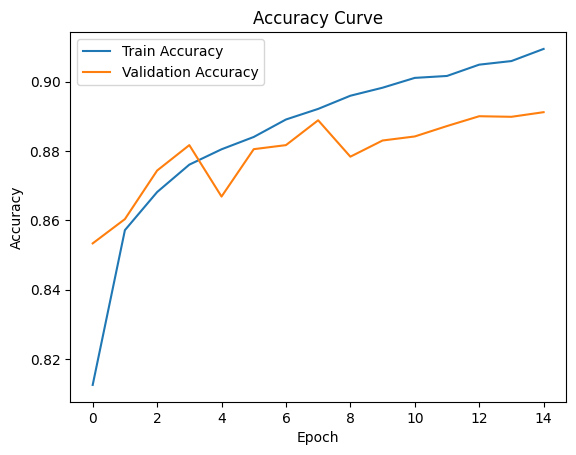

In [61]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

plt.Figure(figsize=(4, 10))
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()


In [63]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
from google.colab import files

y_pred = []
model_ANN.eval()
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)
        outputs = model_ANN(X_batch)
        predicted = torch.argmax(outputs, dim=1)
        y_pred.extend(predicted.cpu().numpy())

torch.save(model_ANN.state_dict(), "model_ANN.pth")
files.download("model_ANN.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [ ]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.


class CNN(nn.Module):
    def __init__(self, input_channels=1, num_classes=10):
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(input_channels, 32, kernel_size=3, stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # Sesuaikan ukuran input dengan output dari conv/pool
        self.fc2 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.flatten(x)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

In [67]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.


train_loader = DataLoader(TensorDataset(X_train_tensor.view(-1, 1, 28, 28), y_train_tensor), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor.view(-1, 1, 28, 28), y_val_tensor), batch_size=32, shuffle=False)


Model_CNN = CNN().to(device)
optimizer_CNN = Adam(Model_CNN.parameters(), lr=1e-3)
epochs = 20
history_CNN = train_model(
    Model_CNN, train_loader, val_loader, loss_fn, optimizer_CNN, num_epochs=epochs, device=device
)


Epoch [1/20], Train Loss: 0.5033, Train Acc: 0.8191, Val Loss: 0.3214, Val Acc: 0.8858
Epoch [2/20], Train Loss: 0.3413, Train Acc: 0.8792, Val Loss: 0.2744, Val Acc: 0.8997
Epoch [3/20], Train Loss: 0.2913, Train Acc: 0.8953, Val Loss: 0.2544, Val Acc: 0.9110
Epoch [4/20], Train Loss: 0.2644, Train Acc: 0.9047, Val Loss: 0.2415, Val Acc: 0.9138
Epoch [5/20], Train Loss: 0.2378, Train Acc: 0.9144, Val Loss: 0.2488, Val Acc: 0.9132
Epoch [6/20], Train Loss: 0.2228, Train Acc: 0.9204, Val Loss: 0.2466, Val Acc: 0.9148
Epoch [7/20], Train Loss: 0.2088, Train Acc: 0.9230, Val Loss: 0.2538, Val Acc: 0.9072
Epoch [8/20], Train Loss: 0.1907, Train Acc: 0.9290, Val Loss: 0.2474, Val Acc: 0.9148
Epoch [9/20], Train Loss: 0.1791, Train Acc: 0.9339, Val Loss: 0.2592, Val Acc: 0.9147
Epoch [10/20], Train Loss: 0.1677, Train Acc: 0.9362, Val Loss: 0.2682, Val Acc: 0.9123
Epoch [11/20], Train Loss: 0.1593, Train Acc: 0.9397, Val Loss: 0.2648, Val Acc: 0.9135
Epoch [12/20], Train Loss: 0.1481, Train 

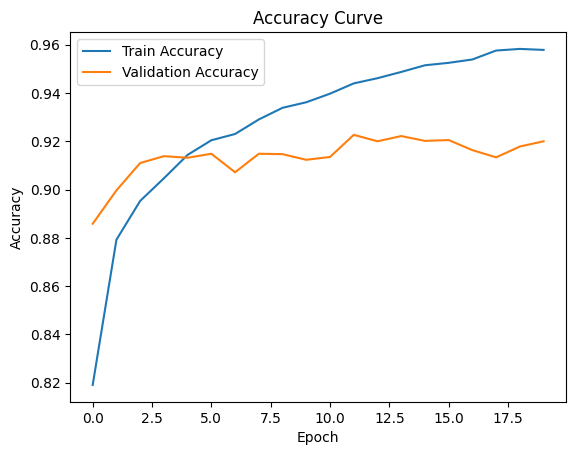

In [69]:
plt.Figure(figsize=(4, 10))
plt.plot(history_CNN["train_acc"], label="Train Accuracy")
plt.plot(history_CNN["val_acc"], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

overfit di epoch awal (3-4)

In [77]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
from sklearn.metrics import accuracy_score
y_pred_CNN = []
Model_CNN.eval()
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.view(-1, 1, 28, 28).to(device)
        outputs = Model_CNN(X_batch)
        predicted = torch.argmax(outputs, dim=1)
        y_pred_CNN.extend(predicted.cpu().numpy())

print(accuracy_score(y_test, y_pred_CNN))

0.9255


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [72]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNN_BN_Dropout(nn.Module):
    def __init__(self, input_channels=1, num_classes=10):
        super(CNN_BN_Dropout, self).__init__()
        self.conv1 = nn.Conv2d(input_channels, 32, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)  # Sesuaikan ukuran input dengan output dari conv/pool
        self.fc2 = nn.Linear(128, num_classes)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.flatten(x)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x


Epoch [1/20], Train Loss: 0.5154, Train Acc: 0.8154, Val Loss: 0.3216, Val Acc: 0.8803
Epoch [2/20], Train Loss: 0.3613, Train Acc: 0.8712, Val Loss: 0.2792, Val Acc: 0.8982
Epoch [3/20], Train Loss: 0.3131, Train Acc: 0.8889, Val Loss: 0.2489, Val Acc: 0.9087
Epoch [4/20], Train Loss: 0.2863, Train Acc: 0.8962, Val Loss: 0.2558, Val Acc: 0.9047
Epoch [5/20], Train Loss: 0.2589, Train Acc: 0.9059, Val Loss: 0.2471, Val Acc: 0.9138
Epoch [6/20], Train Loss: 0.2442, Train Acc: 0.9109, Val Loss: 0.2436, Val Acc: 0.9137
Epoch [7/20], Train Loss: 0.2284, Train Acc: 0.9169, Val Loss: 0.2245, Val Acc: 0.9183
Epoch [8/20], Train Loss: 0.2123, Train Acc: 0.9223, Val Loss: 0.2291, Val Acc: 0.9193
Epoch [9/20], Train Loss: 0.1992, Train Acc: 0.9267, Val Loss: 0.2298, Val Acc: 0.9208
Epoch [10/20], Train Loss: 0.1883, Train Acc: 0.9301, Val Loss: 0.2341, Val Acc: 0.9238
Epoch [11/20], Train Loss: 0.1791, Train Acc: 0.9323, Val Loss: 0.2486, Val Acc: 0.9202
Epoch [12/20], Train Loss: 0.1697, Train 

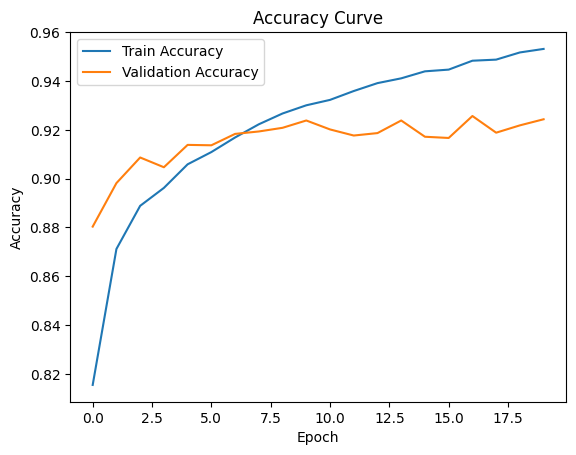

In [73]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

model_CNN_BN_Dropout = CNN_BN_Dropout().to(device)
optimizer_CNN_BN_Dropout = Adam(model_CNN_BN_Dropout.parameters(), lr=1e-3)
epochs = 20
history_CNN_BN_Dropout = train_model(
    model_CNN_BN_Dropout, train_loader, val_loader, loss_fn, optimizer_CNN_BN_Dropout, num_epochs=epochs, device=device
)

plt.Figure(figsize=(4, 10))
plt.plot(history_CNN_BN_Dropout["train_acc"], label="Train Accuracy")
plt.plot(history_CNN_BN_Dropout["val_acc"], label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

Baik dengan CNN versi ini dan yg sebelumnya, mereka memiliki akurasi yang nyaris identik dan pola curve yang sama. bedanya, model dengan Batch Normalization dan Dropout lebih stabil dan tidak overfit di epoch awal (mulai di epoch 6+)

In [75]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
from sklearn.metrics import accuracy_score

y_pred_CNN_BN_Dropout = []
model_CNN_BN_Dropout.eval()
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.view(-1, 1, 28, 28).to(device)
        outputs = model_CNN_BN_Dropout(X_batch)
        predicted = torch.argmax(outputs, dim=1)
        y_pred_CNN_BN_Dropout.extend(predicted.cpu().numpy())

print(accuracy_score(y_test, y_pred_CNN_BN_Dropout))

0.9282


# 4. Evaluasi Model

In [81]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

eval_results = []

models_info = [
    ("ANN", y_pred, model_ANN),
    ("CNN", y_pred_CNN, Model_CNN),
    ("CNN_BN_Dropout", y_pred_CNN_BN_Dropout, model_CNN_BN_Dropout),
]

for model_name, preds, model_obj in models_info:
    accuracy = accuracy_score(y_test, preds)
    report = classification_report(y_test, preds, output_dict=True, zero_division=0)
    
    eval_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1-Score": report["macro avg"]["f1-score"],
        "Num Parameters": sum(p.numel() for p in model_obj.parameters()),
    })

eval_df = pd.DataFrame(eval_results)
eval_df

,Model,Accuracy,Precision,Recall,F1-Score,Num Parameters
0,ANN,0.8895,0.891407,0.8895,0.888331,242762
1,CNN,0.9255,0.925327,0.9255,0.925251,421642
2,CNN_BN_Dropout,0.9282,0.928606,0.9282,0.928323,421834


In [104]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
best_model_preds = y_pred_CNN_BN_Dropout  

# Add output_dict=True so it returns a dictionary instead of a string
best_model_report = classification_report(
    y_test, 
    best_model_preds, 
    target_names=[class_names[i] for i in range(10)], 
    zero_division=0,
    output_dict=True
)

best_model_report_df = pd.DataFrame(best_model_report).transpose()
display(best_model_report_df)



,precision,recall,f1-score,support
T-shirt/top,0.889115,0.8740,0.881493,1000.0000
Trouser,0.991960,0.9870,0.989474,1000.0000
Pullover,0.911642,0.8770,0.893986,1000.0000
Dress,0.921053,0.9450,0.932873,1000.0000
Coat,0.889328,0.9000,0.894632,1000.0000
Sandal,0.982983,0.9820,0.982491,1000.0000
Shirt,0.780915,0.8020,0.791317,1000.0000
Sneaker,0.966700,0.9580,0.962330,1000.0000
Bag,0.988922,0.9820,0.985449,1000.0000
Ankle boot,0.963439,0.9750,0.969185,1000.0000


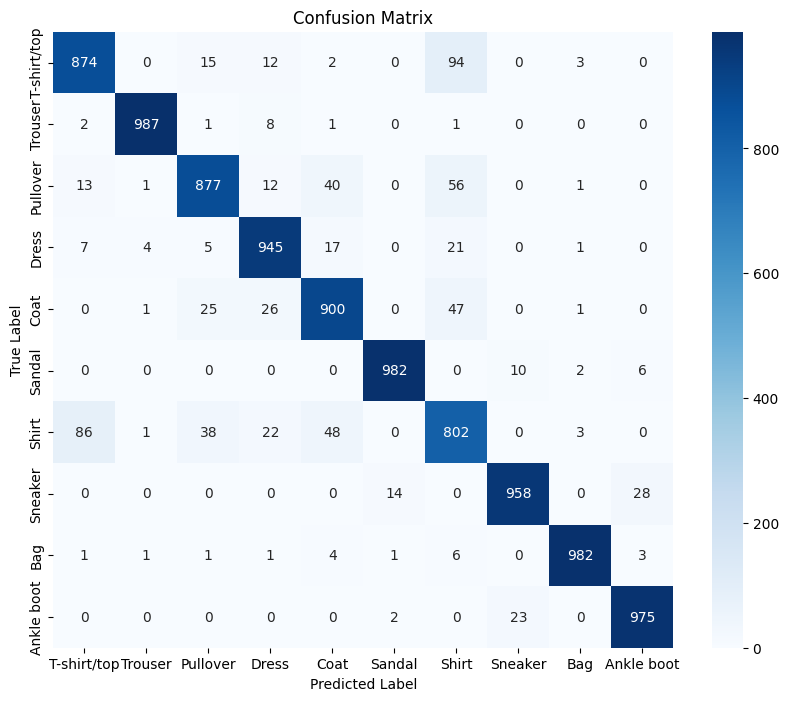

In [105]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

plt.figure(figsize=(10, 8))
confusion_matrix = pd.crosstab(pd.Series(y_test, name='Actual'), pd.Series(best_model_preds, name='Predicted'))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=[class_names[i] for i in range(10)], yticklabels=[class_names[i] for i in range(10)])
plt.title("Confusion Matrix") 
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

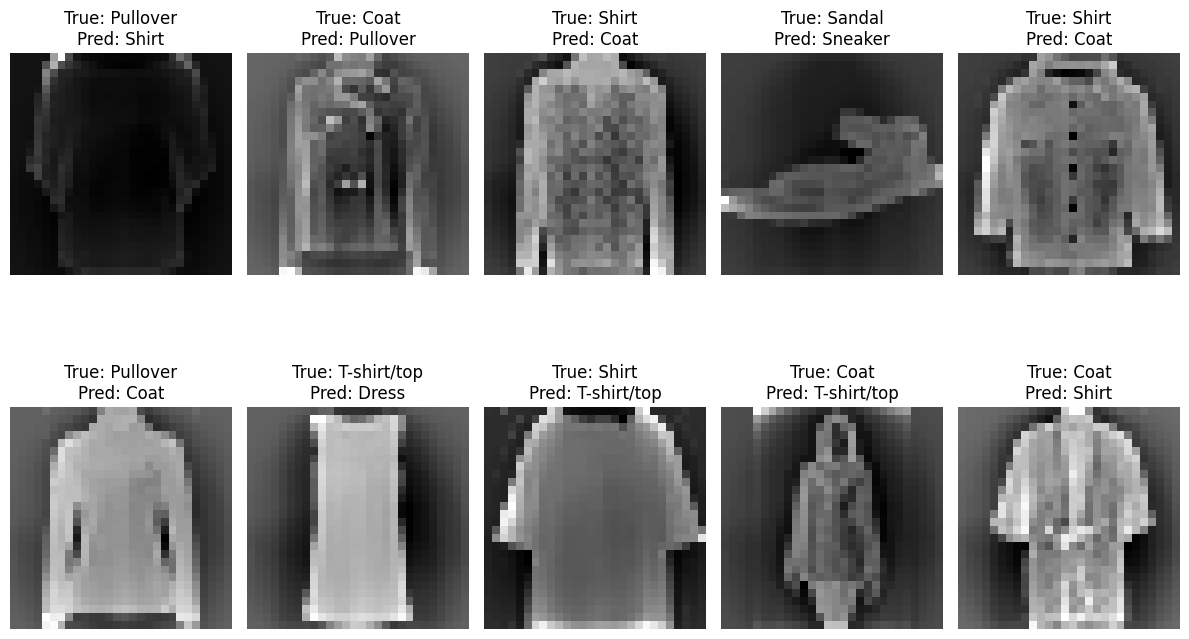

In [96]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

y_test_tensor = torch.tensor(y_test, dtype=torch.long).squeeze()  # Mengubah bentuk menjadi (N,)
misclassified_indices = np.where(y_test != best_model_preds)[0]
plt.figure(figsize=(12, 8))
for i, idx in enumerate(misclassified_indices[:10]):  # Tampilkan 10 contoh
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[best_model_preds[idx]]}")
    plt.axis('off')
plt.tight_layout()



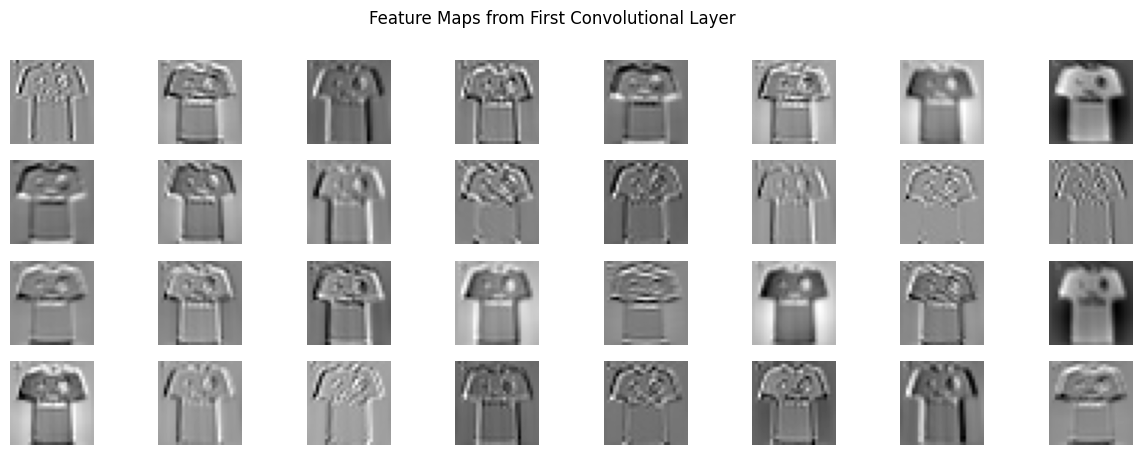

In [97]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

feature_map = model_CNN_BN_Dropout.conv1(X_test_tensor[0].view(1, 1, 28, 28).to(device)).detach().cpu().numpy()
num_filters = feature_map.shape[1]
plt.figure(figsize=(15, 5))
for i in range(num_filters):
    plt.subplot(4, 8, i + 1)
    plt.imshow(feature_map[0, i], cmap='gray')
    plt.axis('off')
plt.suptitle("Feature Maps from First Convolutional Layer")
plt.show()

In [103]:
Model_CNN

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
)

In [ ]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

best_model = model_CNN_BN_Dropout
torch.save(best_model.state_dict(), "model_CNN_BN_Dropout.pth")


In [110]:
from google.colab import drive
import os
import shutil

# 1. Mount Google Drive (ikuti pop-up otorisasi akun Google di bagian atas VS Code)
drive.mount('/content/drive')

# 2. Buat direktori khusus di Google Drive
project_dir = "/content/drive/MyDrive/Praktikum_ML_DL"
os.makedirs(project_dir, exist_ok=True)

# 3. Salin model_ANN.pth yang sudah dilatih ke Google Drive
shutil.copy("model_ANN.pth", f"{project_dir}/model_ANN.pth")
print(f"Tersimpan di: {project_dir}/model_ANN.pth")

# 4. Salin model_CNN_BN_Dropout.pth yang sudah dilatih ke Google Drive
shutil.copy("model_CNN_BN_Dropout.pth", f"{project_dir}/model_CNN_BN_Dropout.pth")
print(f"Tersimpan di: {project_dir}/model_CNN_BN_Dropout.pth")

Mounted at /content/drive
Tersimpan di: /content/drive/MyDrive/Praktikum_ML_DL/model_ANN.pth
Tersimpan di: /content/drive/MyDrive/Praktikum_ML_DL/model_CNN_BN_Dropout.pth


In [111]:
#download 
shutil.copy(f"{project_dir}/model_ANN.pth", "model_ANN.pth")
shutil.copy(f"{project_dir}/model_CNN_BN_Dropout.pth", "model_CNN_BN_Dropout.pth")

'model_CNN_BN_Dropout.pth'

# 5. Analisis

Dataset Fashion-MNIST berisi 60.000 gambar train dan 10.000 gambar test berukuran 28×28 piksel grayscale, terbagi menjadi 10 kelas pakaian yang seimbang (6.000 gambar per kelas di train, 1.000 di test). EDA (bar plot distribusi kelas dan contoh gambar per kelas) menunjukkan kelas tersebut secara visual saling mirip, terutama pakaian atas (T-shirt/top, Shirt, Pullover, Coat, Dress). Semua eksperimen dijalankan pada device cuda (Google Colab GPU). Preprocessing: StandardScaler pada piksel, split train 90%/val 10% dengan stratify, tensor bentuk (N, 1, 28, 28).

Hasil evaluasi pada test set (berdasarkan tabel evaluasi yang dihasilkan code):

| Model | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) | Parameter |
|---|---|---|---|---|---|
| ANN | 0.8895 | 0.8914 | 0.8895 | 0.8883 | 242.762 |
| CNN | 0.9255 | 0.9253 | 0.9255 | 0.9253 | 421.642 |
| CNN_BN_Dropout | 0.9282 | 0.9286 | 0.9282 | 0.9283 | 421.834 |

Catatan analisis:
1. ANN (baseline, input di-flatten ke 784 piksel) mencapai accuracy test 0.8895. Learning curve-nya menunjukkan overfitting mulai terlihat di epoch awal (3-4): train accuracy terus naik sementara val accuracy stagnan. ANN kurang cocok untuk citra karena mengabaikan struktur spasial 2D gambar.
2. CNN sederhana (2 blok Conv2d → ReLU → MaxPool2d, dropout 0.5 sebelum output) naik ke accuracy test 0.9255. Namun learning curve-nya menunjukkan overfitting: val loss mulai naik sejak sekitar epoch 8-9 (0.24 → 0.3664 pada epoch 20) sementara train loss terus menurun ke 0.1094. Model telah menangkap pola spasial citra namun mulai menghafal train set.
3. CNN_BN_Dropout (menambahkan Batch Normalization setelah setiap layer konvolusi) mencapai accuracy test tertinggi 0.9282. Learning curve-nya lebih stabil: tidak overfit di epoch awal (stabil mulai epoch 6+), val acc sekitar 0.92-0.925, dan jarak train-val loss lebih kecil dibanding CNN sederhana. BatchNorm membantu stabilisasi training, sementara Dropout 0.5 mencegah overfitting pada layer fully-connected.
4. CNN memiliki parameter lebih banyak (421 ribu) dibanding ANN (243 ribu) karena lapisan konvolusi, namun performanya secara konsisten lebih baik karena bias inductif struktur citra (hierarki spasial dan parameter sharing melalui filter konvolusi).
5. Classification report model terbaik (CNN_BN_Dropout): performa terendah pada kelas Shirt (precision 0.7809, recall 0.8020, F1 0.7913). Kelas terbaik: Trouser, Bag, Sandal (F1 0.98) karena bentuk sangat karakteristik. Confusion matrix dan visualisasi 10 gambar misclassified mengonfirmasi kebingungan model antara pakaian atas serupa (T-shirt/top, Shirt, Pullover, Coat, Dress). Feature map dari layer konvolusi pertama menangkap pola tepi dan tekstur dasar pada masing-masing filter.

# 6. Kesimpulan dan Saran

## Kesimpulan
- CNN outperforms ANN secara signifikan pada klasifikasi citra Fashion-MNIST (accuracy 0.9282 vs 0.8895) karena CNN memanfaatkan struktur spasial 2D gambar melalui konvolusi, sedangkan ANN hanya memperlakukan piksel sebagai vektor flat tanpa induktif bias spasial.
- Model terbaik adalah CNN dengan Batch Normalization dan Dropout (CNN_BN_Dropout), accuracy test 0.9282 dan F1-score macro 0.9283, dengan learning curve paling stabil tanpa overfitting di epoch awal.
- Batch Normalization membantu stabilisasi training (val loss/acc lebih konsisten), dan Dropout 0.5 mencegah overfitting pada layer fully-connected. Keduanya bersama lebih baik dari CNN sederhana yang overfit sejak sekitar epoch 8-9.
- Kelas yang sulit dibedakan model: Shirt, T-shirt/top, Pullover, Coat, Dress (pakaian atas berbentuk serupa). Kelas yang mudah dikenali: Trouser, Bag, Sandal, Ankle boot (bentuk karakteristik).

## Saran
- Tambah data augmentasi (rotasi, shift, flip kecil) untuk memperkaya variasi pelatihan, terutama pada kelas pakaian atas yang sering salah klasifikasi.
- Coba arsitektur CNN lebih dalam (lebih banyak blok konvolusi) atau transfer learning jika data pelatihan terbatas.
- Lakukan hyperparameter tuning (learning rate, ukuran filter, dropout rate) dengan early stopping berdasarkan val loss.
- Analisis confusion matrix per kelas untuk menyesuaikan strategi pelatihan (misalnya class weight atau threshold) pada kelas yang krusial.